In [16]:
from google.colab import userdata
import os

os.environ["CARTO_API_KEY"] = userdata.get("CARTO_API_KEY")

In [1]:
!git clone https://github.com/talalhaider9/LucidMA2.0.git
%cd LucidMA2.0
!pip install -q -e .

Cloning into 'LucidMA2.0'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 47 (delta 17), reused 37 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 244.66 KiB | 4.01 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/LucidMA2.0
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.4/113.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.8/98.8 kB 9.3 MB/s eta 0:00:00
  Building editable for lucid-ma (pyproject.toml) ... done


In [17]:
!python -m lucid_ma --query "theft from motor vehicle" --limit 50000

I0000 00:00:1792517549.446460   14874 pjrt_api.cc:119] GetPjrtApi was found for TPU at /usr/local/lib/python3.13/dist-packages/libtpu/libtpu.so
I0000 00:00:1792517550.121751   14874 device_rt.cc:166] PjRt runtime initialization deferred for tpu
Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
I0000 00:00:1792517550.124706   14874 libtpu_version.cc:63] Setting libtpu version to: 0.0.50
Analyzing query: theft from motor vehicle
Fetching Chicago crime data...
Cleaned data: 50,000 records
Knowledge graph: 19,784 nodes, 45,818 edges
Loading weights: 100% 103/103 [00:00<00:00, 8441.72it/s]
--- VERIFIED CHICAGO CRIME PROFILE ---
Crime type: THEFT
Records: 10677 (10647 have coordinate data)
Coverage: 2026-07-28T13:30:00+00:00 to 2026-10-12T00:00:00+00:00
Peak observed hour: 15:00
Arrest rate: 8.4% | Domestic-related rate: 5.6%
Top descriptions: $500 AND 

In [18]:
!pip install -q -e ".[agents]"

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lucid-ma (pyproject.toml) ... done


In [32]:
!apt-get update -qq
!apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh
!which ollama
!ollama --version

ERROR: Could not find a version that satisfies the requirement lspci (from versions: none)
ERROR: No matching distribution found for lspci
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
/usr/local/bin/ollama
ollama version is 0.40.6


In [19]:
!nohup ollama serve > /tmp/ollama.log 2>&1 &
!sleep 8
!ollama list

/bin/bash: line 1: ollama: command not found


In [34]:
!ollama pull deepseek-r1:1.5b

In [21]:
!ollama list

/bin/bash: line 1: ollama: command not found


In [22]:
%pip install -q "ag2[openai]"

In [33]:
import shutil
import subprocess
import time
import requests

ollama_path = shutil.which("ollama")
assert ollama_path, "Ollama installation failed or the executable is not on PATH"

ollama_log = open("/tmp/ollama.log", "w")
ollama_process = subprocess.Popen(
    [ollama_path, "serve"],
    stdout=ollama_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=2).ok:
            print("Ollama is ready")
            break
    except requests.RequestException:
        pass
    time.sleep(2)
else:
    raise RuntimeError("Ollama did not start; inspect /tmp/ollama.log")

Ollama is ready


In [35]:
%cd /content/LucidMA2.0
!python -m lucid_ma --query "assault" --limit 30000 --agents

/content/LucidMA2.0
I0000 00:00:1792518459.951150   20769 pjrt_api.cc:119] GetPjrtApi was found for TPU at /usr/local/lib/python3.13/dist-packages/libtpu/libtpu.so
I0000 00:00:1792518460.624260   20769 device_rt.cc:166] PjRt runtime initialization deferred for tpu
Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
I0000 00:00:1792518460.627261   20769 libtpu_version.cc:63] Setting libtpu version to: 0.0.50
Analyzing query: assault
Fetching Chicago crime data...
Cleaned data: 30,000 records
Knowledge graph: 15,170 nodes, 31,892 edges
Loading weights: 100% 103/103 [00:00<00:00, 8547.95it/s]
--- VERIFIED CHICAGO CRIME PROFILE ---
Crime type: ASSAULT
Records: 2979 (2972 have coordinate data)
Coverage: 2026-08-27T04:06:00+00:00 to 2026-10-12T00:00:00+00:00
Peak observed hour: 15:00
Arrest rate: 12.2% | Domestic-related rate: 26.7%
Top descriptions: SIMP

In [36]:
print(open("outputs/analysis.md", encoding="utf-8").read())

# Assault analysis

Query: `assault`

- Records analyzed: 2979
- Records with coordinates: 2972
- Coverage: 2026-08-27T04:06:00+00:00 to 2026-10-12T00:00:00+00:00
- Peak observed hour: 15:00
- Arrest rate: 12.2%
- Domestic-related rate: 26.7%

## Top descriptions

- SIMPLE: 1994
- AGGRAVATED - HANDGUN: 495
- AGGRAVATED - KNIFE / CUTTING INSTRUMENT: 232
- AGGRAVATED - OTHER DANGEROUS WEAPON: 138
- PROTECTED EMPLOYEE - HANDS, FISTS, FEET, NO / MINOR INJURY: 49
- AGGRAVATED POLICE OFFICER - HANDS, FISTS, FEET, NO INJURY: 31
- AGGRAVATED - OTHER FIREARM: 13
- AGGRAVATED PROTECTED EMPLOYEE - OTHER DANGEROUS WEAPON: 6
- AGGRAVATED POLICE OFFICER - HANDGUN: 5
- AGGRAVATED PROTECTED EMPLOYEE - HANDGUN: 5

## Top location types

- APARTMENT: 730
- STREET: 628
- RESIDENCE: 334
- SIDEWALK: 249
- RESTAURANT: 81
- ALLEY: 70
- SMALL RETAIL STORE: 67
- GAS STATION: 65
- PARKING LOT / GARAGE (NON RESIDENTIAL): 59
- SCHOOL - PUBLIC GROUNDS: 58

## Top community areas

- 25: 157
- 43: 120
- 71: 113
- 29

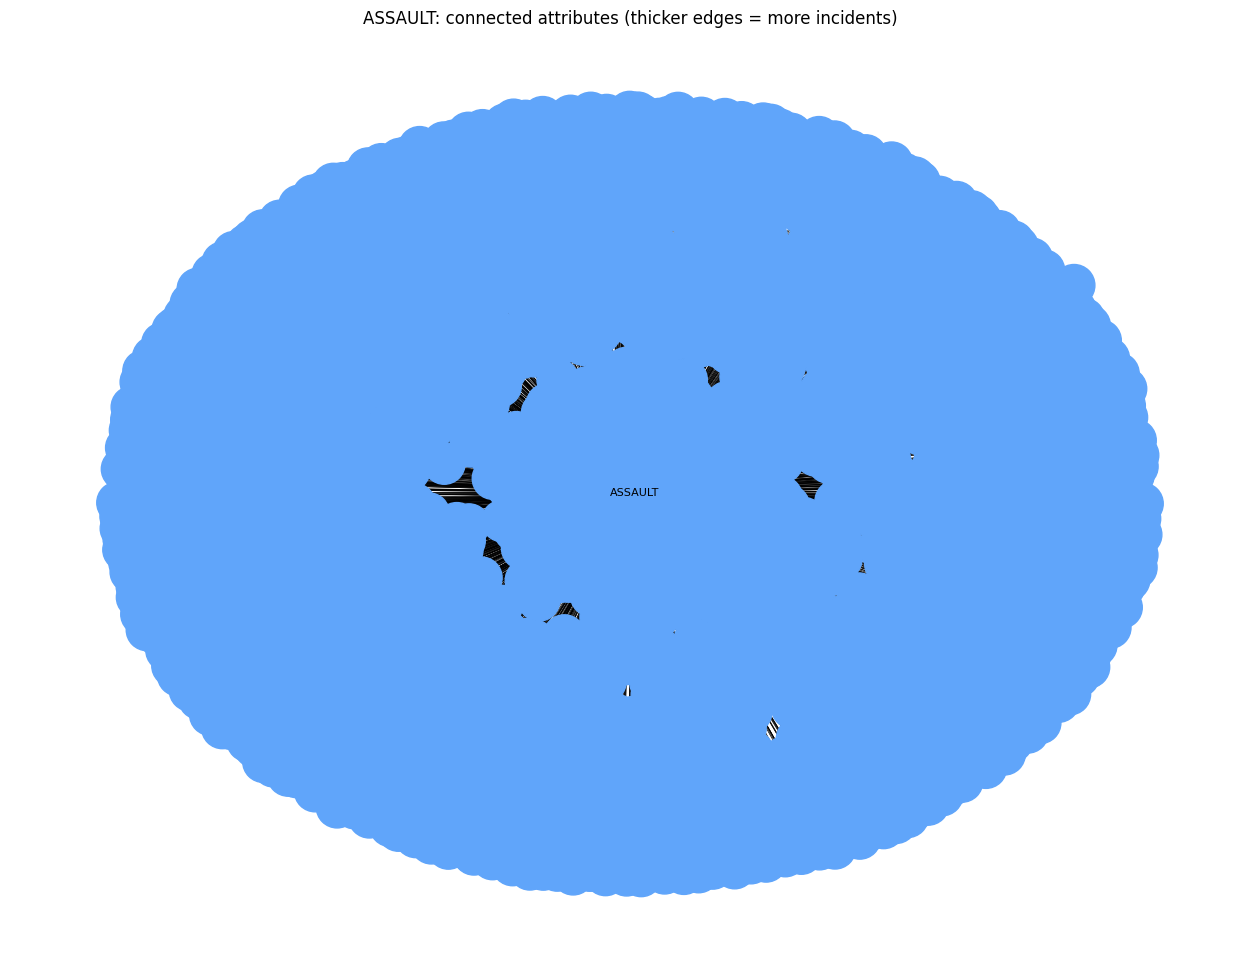

In [25]:
import sys
sys.path.insert(0, "/content/LucidMA2.0/src")

from lucid_ma.data import fetch_crime_data, build_crime_graph
from lucid_ma.data import fetch_crime_data, build_crime_graph
import networkx as nx
import matplotlib.pyplot as plt

df = fetch_crime_data()
graph = build_crime_graph(df)

crime_type = "ASSAULT"
crime_node = f"crime:{crime_type}"

# Keep the selected crime and its directly connected attributes
nodes = [crime_node] + list(graph.neighbors(crime_node))
subgraph = graph.subgraph(nodes)

positions = nx.spring_layout(subgraph, seed=7, k=0.8)
node_colors = [
    "#ef4444" if node == crime_node else "#60a5fa"
    for node in subgraph.nodes()
]
edge_widths = [
    max(0.5, subgraph[u][v]["weight"] / 50)
    for u, v in subgraph.edges()
]

plt.figure(figsize=(16, 12))
nx.draw_networkx(
    subgraph,
    positions,
    labels={crime_node: crime_type},
    with_labels=True,
    node_color=node_colors,
    node_size=900,
    font_size=8,
    width=edge_widths,
)
plt.title(f"{crime_type}: connected attributes (thicker edges = more incidents)")
plt.axis("off")
plt.show()